In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Plot aesthetics
sns.set_theme(style="whitegrid")

In [2]:
np.random.seed(42)
n_records = 600

brands = ['Maruti Suzuki', 'Hyundai', 'Tata', 'Mahindra', 'Toyota', 'Honda']
models = {
    'Maruti Suzuki': ['Swift', 'Baleno', 'Brezza'],
    'Hyundai': ['i20', 'Creta', 'Verna'],
    'Tata': ['Nexon', 'Harrier', 'Altroz'],
    'Mahindra': ['Thar', 'Scorpio', 'XUV700'],
    'Toyota': ['Innova', 'Fortuner', 'Glanza'],
    'Honda': ['City', 'Amaze', 'Elevate']
}
fuel_types = ['Petrol', 'Diesel', 'CNG', 'Electric']
transmissions = ['Manual', 'Automatic']
categories = ['Hatchback', 'Sedan', 'SUV']
cities = ['Mumbai', 'Pune', 'Kolhapur', 'Bangalore', 'Delhi']
salespersons = ['Rahul Sharma', 'Sneha Patil', 'Amit Deshmukh', 'Priya Kulkarni']
payment_modes = ['Cash', 'Bank Transfer', 'UPI', 'Finance/Loan']

records = []
for i in range(1, n_records + 1):
    brand = np.random.choice(brands)
    model = np.random.choice(models[brand])
    mfg_year = np.random.randint(2015, 2024)
    p_date = pd.to_datetime(f"{mfg_year}-{np.random.randint(1,13):02d}-{np.random.randint(1,28):02d}")
    s_date = p_date + pd.Timedelta(days=np.random.randint(30, 365))
    fuel = np.random.choice(fuel_types, p=[0.5, 0.3, 0.15, 0.05])
    trans = np.random.choice(transmissions, p=[0.65, 0.35])
    cat = 'SUV' if model in ['Creta', 'Brezza', 'Nexon', 'Harrier', 'Thar', 'Scorpio', 'XUV700', 'Fortuner'] else ('Sedan' if model in ['City', 'Verna'] else 'Hatchback')
    km = np.random.randint(5000, 120000)
    purchase_price = np.random.randint(400000, 2500000)
    # Selling price influenced by condition, brand, and profit margin
    profit = int(purchase_price * np.random.uniform(0.08, 0.22))
    selling_price = purchase_price + profit

    records.append({
        'Car_ID': f"CAR_{1000 + i}",
        'Brand': brand,
        'Model': model,
        'Manufacturing_Year': mfg_year,
        'Purchase_Date': p_date.strftime('%Y-%m-%d'),
        'Selling_Date': s_date.strftime('%Y-%m-%d'),
        'Fuel_Type': fuel,
        'Transmission': trans,
        'Car_Category': cat,
        'Kilometers_Driven': km,
        'Purchase_Price': purchase_price,
        'Selling_Price': selling_price,
        'Profit': profit,
        'Customer_Age': np.random.randint(22, 65),
        'Customer_Gender': np.random.choice(['Male', 'Female']),
        'City': np.random.choice(cities),
        'Salesperson': np.random.choice(salespersons),
        'Payment_Mode': np.random.choice(payment_modes)
    })

df = pd.DataFrame(records)
df.to_csv('car_showroom_data_raw.csv', index=False)
print(f"Dataset ready: {df.shape[0]} rows, {df.shape[1]} columns")

Dataset ready: 600 rows, 18 columns


In [3]:
# Check initial health
print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

# Convert date fields
df['Purchase_Date'] = pd.to_datetime(df['Purchase_Date'])
df['Selling_Date'] = pd.to_datetime(df['Selling_Date'])

# Ensure positive numerical logic and strip string whitespace
df['Brand'] = df['Brand'].str.strip()
df['Model'] = df['Model'].str.strip()

# Outlier check using IQR on Kilometers and Prices
for col in ['Kilometers_Driven', 'Selling_Price']:
    q25, q75 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q75 - q25
    lower, upper = q25 - 1.5 * iqr, q75 + 1.5 * iqr
    print(f"{col} Outlier Bounds: [{lower:.0f}, {upper:.0f}]")

# Save cleaned CSV as requested in deliverables
df.to_csv('cleaned_car_showroom_data.csv', index=False)

Missing values:
 Car_ID                0
Brand                 0
Model                 0
Manufacturing_Year    0
Purchase_Date         0
Selling_Date          0
Fuel_Type             0
Transmission          0
Car_Category          0
Kilometers_Driven     0
Purchase_Price        0
Selling_Price         0
Profit                0
Customer_Age          0
Customer_Gender       0
City                  0
Salesperson           0
Payment_Mode          0
dtype: int64
Duplicates: 0
Kilometers_Driven Outlier Bounds: [-56751, 182590]
Selling_Price Outlier Bounds: [-818264, 4179582]


In [4]:
# 1. Feature Engineering: Calculate Car Age (Task 5)
df['Car_Age'] = df['Selling_Date'].dt.year - df['Manufacturing_Year']

# 2. Recalculate / verify profit margin
df['Calculated_Profit'] = df['Selling_Price'] - df['Purchase_Price']

# 3. Extract transaction date features
df['Selling_Month'] = df['Selling_Date'].dt.month_name()
df['Selling_Year'] = df['Selling_Date'].dt.year

# Quick check on the new columns
df[['Car_ID', 'Manufacturing_Year', 'Car_Age', 'Selling_Price', 'Calculated_Profit', 'Selling_Month']].head()

,Car_ID,Manufacturing_Year,Car_Age,Selling_Price,Calculated_Profit,Selling_Month
0,CAR_1001,2022,0,1933668,293757,October
1,CAR_1002,2016,1,1519164,202124,June
2,CAR_1003,2017,1,1857380,151964,September
3,CAR_1004,2019,0,1432175,135233,June
4,CAR_1005,2020,1,677524,80755,March


In [5]:
print("=" * 40)
print("       BUSINESS METRICS SUMMARY       ")
print("=" * 40)
print(f"Total Cars Sold        : {len(df)}")
print(f"Total Revenue          : ₹{df['Selling_Price'].sum():,}")
print(f"Total Profit           : ₹{df['Profit'].sum():,}")
print(f"Average Purchase Price : ₹{df['Purchase_Price'].mean():,.2f}")
print(f"Average Selling Price  : ₹{df['Selling_Price'].mean():,.2f}")

print("\n--- Top 3 Selling Brands ---")
print(df['Brand'].value_counts().head(3))

print("\n--- Top 3 Selling Models ---")
print(df['Model'].value_counts().head(3))

print("\n--- Revenue by Salesperson ---")
print(df.groupby('Salesperson')['Selling_Price'].sum().sort_values(ascending=False))

print("\n--- Profit by Car Category ---")
print(df.groupby('Car_Category')['Profit'].sum().sort_values(ascending=False))

       BUSINESS METRICS SUMMARY       
Total Cars Sold        : 600
Total Revenue          : ₹1,007,326,572
Total Profit           : ₹129,871,508
Average Purchase Price : ₹1,462,425.11
Average Selling Price  : ₹1,678,877.62

--- Top 3 Selling Brands ---
Brand
Toyota           110
Honda            106
Maruti Suzuki    103
Name: count, dtype: int64

--- Top 3 Selling Models ---
Model
Innova    45
Creta     42
Amaze     40
Name: count, dtype: int64

--- Revenue by Salesperson ---
Salesperson
Sneha Patil       266930545
Rahul Sharma      260771833
Priya Kulkarni    249457331
Amit Deshmukh     230166863
Name: Selling_Price, dtype: int64

--- Profit by Car Category ---
Car_Category
SUV          58865158
Hatchback    58028048
Sedan        12978302
Name: Profit, dtype: int64


/tmp/ipykernel_6052/682416670.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Brand', order=df['Brand'].value_counts().index, ax=axes[0, 0], palette='viridis')
/tmp/ipykernel_6052/682416670.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Brand', y='Selling_Price', ax=axes[2, 1], palette='Set2')


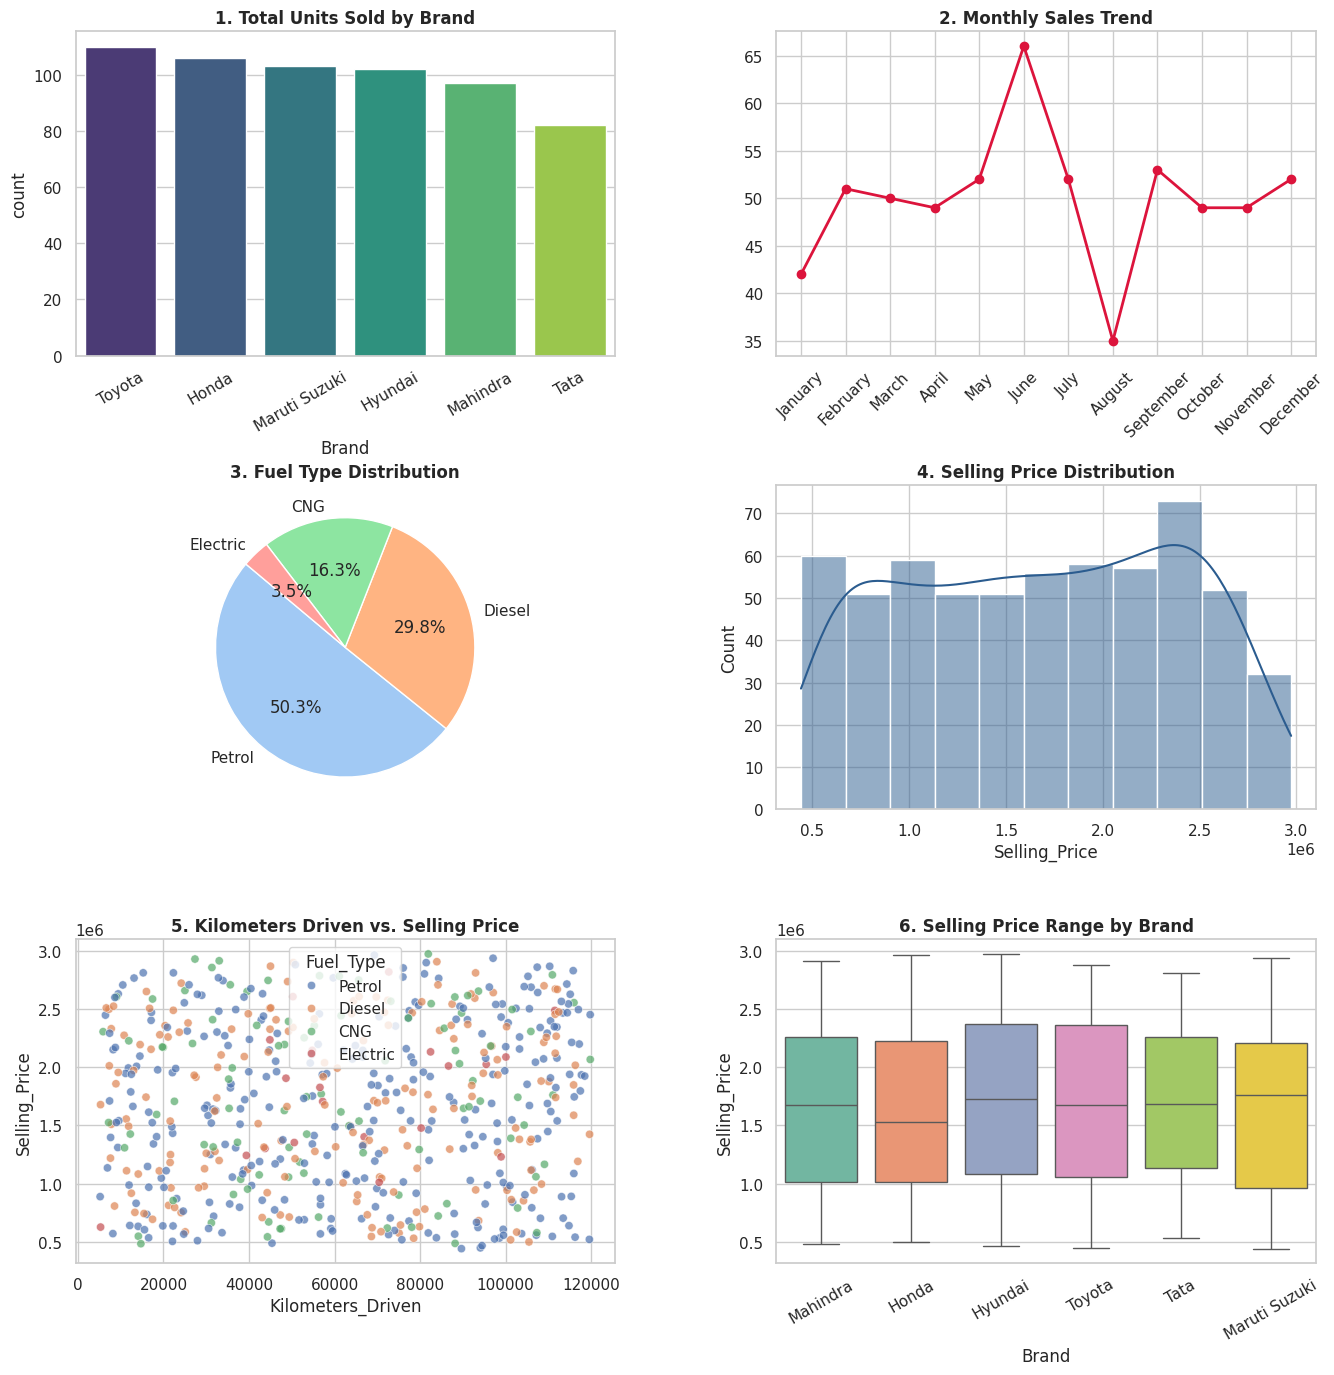

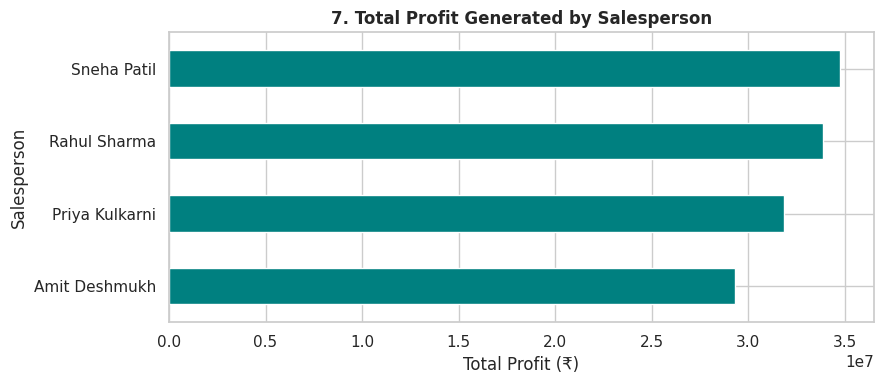

In [6]:
# Task 4: Visualizations
fig, axes = plt.subplots(3, 2, figsize=(16, 16))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# 1. Bar Chart: Sales by Car Brand
sns.countplot(data=df, x='Brand', order=df['Brand'].value_counts().index, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('1. Total Units Sold by Brand', fontsize=12, fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=30)

# 2. Line Chart: Monthly Sales Trends
monthly_order = ['January', 'February', 'March', 'April', 'May', 'June',
                 'July', 'August', 'September', 'October', 'November', 'December']
monthly_counts = df['Selling_Month'].value_counts().reindex(monthly_order).dropna()
axes[0, 1].plot(monthly_counts.index, monthly_counts.values, marker='o', color='crimson', linewidth=2)
axes[0, 1].set_title('2. Monthly Sales Trend', fontsize=12, fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Pie Chart: Fuel Type Distribution
axes[1, 0].pie(df['Fuel_Type'].value_counts(), labels=df['Fuel_Type'].value_counts().index,
               autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
axes[1, 0].set_title('3. Fuel Type Distribution', fontsize=12, fontweight='bold')

# 4. Histogram: Selling Price Distribution
sns.histplot(df['Selling_Price'], kde=True, ax=axes[1, 1], color='#2b5c8f')
axes[1, 1].set_title('4. Selling Price Distribution', fontsize=12, fontweight='bold')

# 5. Scatter Plot: Kilometers vs Selling Price
sns.scatterplot(data=df, x='Kilometers_Driven', y='Selling_Price', hue='Fuel_Type', ax=axes[2, 0], alpha=0.7)
axes[2, 0].set_title('5. Kilometers Driven vs. Selling Price', fontsize=12, fontweight='bold')

# 6. Box Plot: Selling Prices by Brand
sns.boxplot(data=df, x='Brand', y='Selling_Price', ax=axes[2, 1], palette='Set2')
axes[2, 1].set_title('6. Selling Price Range by Brand', fontsize=12, fontweight='bold')
axes[2, 1].tick_params(axis='x', rotation=30)

plt.show()

# 7. Bar Chart: Profit by Salesperson
plt.figure(figsize=(9, 4))
df.groupby('Salesperson')['Profit'].sum().sort_values().plot(kind='barh', color='#008080')
plt.title('7. Total Profit Generated by Salesperson', fontsize=12, fontweight='bold')
plt.xlabel('Total Profit (₹)')
plt.tight_layout()
plt.show()

In [7]:
# Task 6: Machine Learning Model Building & Comparison
X = df[['Brand', 'Manufacturing_Year', 'Fuel_Type', 'Transmission', 'Kilometers_Driven', 'Purchase_Price']]
y = df['Selling_Price']

# Split 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Preprocessing
cat_cols = ['Brand', 'Fuel_Type', 'Transmission']
num_cols = ['Manufacturing_Year', 'Kilometers_Driven', 'Purchase_Price']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ],
    remainder='passthrough'
)

# Models dictionary
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree Regressor': DecisionTreeRegressor(random_state=42, max_depth=8),
    'Random Forest Regressor': RandomForestRegressor(random_state=42, n_estimators=100)
}

results = []

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE (₹)': f"{mae:,.2f}",
        'MSE': f"{mse:,.2f}",
        'RMSE (₹)': f"{rmse:,.2f}",
        'R² Score': round(r2, 4)
    })

comparison_df = pd.DataFrame(results).sort_values(by='R² Score', ascending=False)
print("=" * 60)
print("            MACHINE LEARNING MODEL EVALUATION              ")
print("=" * 60)
comparison_df


            MACHINE LEARNING MODEL EVALUATION              


,Model,MAE (₹),MSE,RMSE (₹),R² Score
0,Linear Regression,"48,212.26","3,851,326,505.73","62,059.06",0.9923
2,Random Forest Regressor,"51,079.18","4,519,761,382.85","67,229.17",0.9909
1,Decision Tree Regressor,"63,825.79","7,277,004,672.14","85,305.36",0.9854


In [8]:
import joblib

# Deliverable 4: Save the trained best model
best_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', LinearRegression())])
best_pipeline.fit(X_train, y_train)

# Save model file
joblib.dump(best_pipeline, 'car_price_prediction_model.joblib')
print("Trained Model saved successfully as 'car_price_prediction_model.joblib'!")

Trained Model saved successfully as 'car_price_prediction_model.joblib'!


In [9]:
# ==========================================
# Task 3 & Business Questions 3, 4, 6 & 9
# ==========================================
print("\n--- Question 3: Preferred Fuel Type ---")
print(df['Fuel_Type'].value_counts())

print("\n--- Question 4: Transmission Type Sold Most ---")
print(df['Transmission'].value_counts())

print("\n--- Question 6 & Task 3: Peak Sales Month & Yearly Trend ---")
print(f"Top Month: {df['Selling_Month'].value_counts().idxmax()} ({df['Selling_Month'].value_counts().max()} units)")
print(df['Selling_Year'].value_counts().sort_index())

print("\n--- Task 3: Sales Comparison (Fuel Type vs. Transmission) ---")
print(pd.crosstab(df['Fuel_Type'], df['Transmission'], margins=True))

print("\n--- Question 9: Average Selling Price by Brand & Fuel Type ---")
print(df.groupby(['Brand', 'Fuel_Type'])['Selling_Price'].mean().round(2))


--- Question 3: Preferred Fuel Type ---
Fuel_Type
Petrol      302
Diesel      179
CNG          98
Electric     21
Name: count, dtype: int64

--- Question 4: Transmission Type Sold Most ---
Transmission
Manual       387
Automatic    213
Name: count, dtype: int64

--- Question 6 & Task 3: Peak Sales Month & Yearly Trend ---
Top Month: June (66 units)
Selling_Year
2015    39
2016    64
2017    80
2018    68
2019    66
2020    68
2021    68
2022    65
2023    50
2024    32
Name: count, dtype: int64

--- Task 3: Sales Comparison (Fuel Type vs. Transmission) ---
Transmission  Automatic  Manual  All
Fuel_Type                           
CNG                  27      71   98
Diesel               68     111  179
Electric              6      15   21
Petrol              112     190  302
All                 213     387  600

--- Question 9: Average Selling Price by Brand & Fuel Type ---
Brand          Fuel_Type
Honda          CNG          1664365.73
               Diesel       1781093.91
          